# 17 - Train a FilmAffinity movie and whole-series hybrid

**Question:** Can the strongest movie-recommender approach so far provide a useful starting point for a model trained on individual ratings of both movies and whole TV series?

Reuse the successful structure: binary item collaborative filtering, text and cast content, and a quality prior. Fit a fresh FilmAffinity model and select a bounded blend on validation data. Here the text is Spanish FilmAffinity metadata and the quality prior comes only from training ratings. This is a new experiment, not the unchanged MovieLens model.

[Notebook 16](16_tv_ratings_dataset_audit.ipynb) audited the source records. This notebook uses its downloaded inputs with hash verification. It makes no paid API calls, does not promote a model into the app, and does not open the previous MovieLens test feedback.

## Prespecified experiment contract

- Keep individual movie/whole-series candidate ratings from users with **at least 10 retained ratings and at least three distinct review dates**. Whole-series candidates use the source audit's high/medium-confidence inference after episode/season exclusions. These labels are inferred, not calibrated probabilities or manually verified ground truth. Movie labels also come from source metadata inference.
- Split each user's complete **review-date groups** chronologically, approximately **60% training / 20% validation / 20% reserved test**. A date group must not straddle boundaries. Review publication dates are proxies for feedback time, not verified historical rating timestamps.
- Define a **like as a rating of 8/10 or higher**. Lower training ratings remain observed items and are excluded from recommendations. Do not treat unobserved titles as explicit dislikes.
- Fit vocabularies, TF-IDF/feature weights, collaborative features, and the Bayesian quality prior using training data only. The recommendation candidate catalog contains training-rated titles only.
- Exclude every title rated in the user's training history, including low ratings. Keep all held-out likes in Recall and ideal-NDCG denominators, including titles unavailable in the training candidate catalog.
- Select the bounded validation grid by **the mean of movie Recall@10 and TV Recall@10**. Also report each domain's metrics and mixed-catalog Recall@10/NDCG@10. Candidate sets, labels, users, and tie rules stay fixed across variants.
- Reserve the new FilmAffinity test feedback. Do not read it for model selection or report its recommendation accuracy in this notebook.

The helper saves the exact split, eligible population, model grid, selection rule, source identities, and fitted model so the reported experiment can be reproduced.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (path / 'scripts/filmaffinity_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the movie-recommendation-system project.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.filmaffinity_experiment import run_experiment

OUTPUT = ROOT / 'data/processed/notebook17_filmaffinity'
print(f'Project: {ROOT}')
print('Offline training and validation experiment; reserved test feedback stays unread.')

Project: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system
Offline training and validation experiment; reserved test feedback stays unread.


## Models and feature boundaries

Compare a bounded grid built from **binary item collaborative filtering**, **Spanish TF-IDF text plus genres**, **cast-name features**, and a **training-only Bayesian prior**. The source provides cast names rather than an audited IMDb-person crosswalk; shared names can be ambiguous.

Movies and series share the FilmAffinity user-ID namespace. Their collaborative relationships can therefore be learned from observed ratings by the same users. This does not require identifying any user as a MovieLens user.

The quality signal here is distinct from the previous experiment's IMDb aggregate adjustment. No validation or reserved-test ratings may contribute to the new prior. Current catalog descriptions and cast metadata are not historical snapshots at each user's review date.

The blend is additive: **CF + p × synopsis + m × (genres + cast)/2 + q × quality**. CF and each content component are scaled by the user's maximum unseen-item score before task filtering. Cast identity uses Unicode normalization, case and whitespace, without an external person-ID crosswalk.


In [2]:
report = run_experiment(ROOT)
report_path = OUTPUT / 'experiment_report.json'
assert report_path.is_file(), 'The experiment did not save its report.'
print(f'Saved report: {report_path}')

Verifying audited inputs; preparing frozen FilmAffinity-only split...
Training on 173,232 ratings from 5,505 users, 10,722 titles...
Validated 128/5,505 users against 15 models.
Validated 1,024/5,505 users against 15 models.
Validated 2,048/5,505 users against 15 models.
Validated 3,072/5,505 users against 15 models.
Validated 4,096/5,505 users against 15 models.
Validated 5,120/5,505 users against 15 models.
Validated 5,505/5,505 users against 15 models.
Selected on balanced validation Recall@10: Training popularity
Saved report: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\processed\notebook17_filmaffinity\experiment_report.json


## Population, split, and catalog coverage

Check the actual retained population before interpreting model scores. FilmAffinity's review-associated scores are a selected subset of user ratings, not a complete random sample of all ratings on the service. Eligibility filtering further changes the population.

Coverage distinguishes whether a held-out liked title can be recommended at all from whether the model ranks it well. A title absent from the training catalog still counts in the metric denominator.

In [3]:
display(report['scope'])
display(report['split'])
display(report['dataset'])
display(pd.DataFrame(report['coverage']))
coverage = pd.read_csv(OUTPUT / 'coverage.csv')
display(coverage.head(12))


{'evaluation_split': 'validation',
 'reserved_test_evaluated': False,
 'reserved_test_policy': 'Constructed/exported only; never loaded by fitting, ranking or model selection.',
 'movielens_feedback_read': False,
 'paid_api_calls': False,
 'app_changed': False,
 'ratings': 'Review-associated FilmAffinity scores only; reviewer and snapshot selection bias.',
 'units': 'Inferred movie entries and high/medium heuristic whole-series candidates; episodes, seasons, uncertain units excluded.',
 'identity': 'FilmAffinity IDs and normalized cast names; no verified IMDb/TMDB crosswalk, possible cast-name collisions.',
 'chronology': 'Per-user review-day proxy, not verified original rating chronology or a global as-of cutoff; current metadata can postdate ratings.',
 'generalization': 'Retrospective established-user cohort; new users, unseen-title cold start, groups, and LLM comparisons not evaluated.',
 'selection': 'Equal movie/TV weighting targets balanced service; movie and TV cohorts differ a

{'split_id': 'filmaffinity_review_date_groups_60_20_20_v1',
 'eligible_users': 5505,
 'min_ratings': 10,
 'min_distinct_review_dates': 3,
 'input_ratings': 392039,
 'excluded_history_ratings': 103049,
 'rows': {'train': 173232, 'validation': 57995, 'reserved_test': 57763},
 'actual_fractions': {'train': 0.5994394269697914,
  'validation': 0.2006816844873525,
  'reserved_test': 0.19987888854285615},
 'policy': 'Nearest cumulative 60%, then 80%; whole UTC review-day groups; ties earlier; no score-based cuts.',
 'eligibility': 'Retrospective minimum-history cohort, determined by counts and dates only; not a new-user study.',
 'time_limitation': 'Review publication dates are proxies, not verified rating timestamps; current snapshot metadata.',
 'files': {'train.csv': 'f44355b65e6a5d57e26a65240e05dfdf588788077710052c1bf23f98b4beae5f',
  'validation.csv': '05987ee1e843aa766d0f92312e9a518b610f297abb68e0e250701e16fbe4a722',
  'reserved_test.csv': 'c3f1c462148b85c5f83e2325b4d3534f395a626a352621

{'training_ratings': 173232,
 'validation_ratings': 57995,
 'training_users': 5505,
 'training_catalog_titles': 10722,
 'training_catalog_units': {'movie': 8995, 'whole_series': 1727},
 'training_ratings_units': {'movie': 162535, 'whole_series': 10697},
 'users_without_training_likes': 292,
 'catalog_without_training_likes': 4526,
 'missing_feature_items': {'cf': 4526,
  'synopsis': 6,
  'genres': 0,
  'cast': 238}}

,task,users,positives,available,mean_available_fraction,mean_recall_ceiling_at_10
0,mixed,4146,17410,17216,0.988215,0.956089
1,movie,3830,15625,15520,0.993530,0.962195
2,whole_series,985,1785,1696,0.959216,0.957486


,user_id,task,positives,available,available_fraction,recall_ceiling_at_10,train_likes,train_tv_likes
0,fa:100146,mixed,1,1,1.0,1.000000,3,0
1,fa:100146,movie,1,1,1.0,1.000000,3,0
2,fa:100229,mixed,3,3,1.0,1.000000,10,0
3,fa:100229,movie,3,3,1.0,1.000000,10,0
4,fa:100341,mixed,1,1,1.0,1.000000,9,0
5,fa:100341,movie,1,1,1.0,1.000000,9,0
6,fa:100948,mixed,76,76,1.0,0.131579,244,0
7,fa:100948,movie,76,76,1.0,0.131579,244,0
8,fa:100954,mixed,2,2,1.0,1.000000,12,0
9,fa:100954,movie,2,2,1.0,1.000000,12,0


## Validation comparison

The selection objective balances movie and TV Recall@10 rather than allowing the more numerous movie labels to dominate one mixed average. Compare domain metrics alongside mixed ranking performance. The new scores describe this FilmAffinity protocol and population; they are **not directly comparable to earlier MovieLens or LLM scores**.

All rows below are validation results from the prespecified bounded grid. No reserved-test scores are used to choose a winner.

,model,kind,plot,metadata,quality,mixed_users,mixed_recall_at_10,mixed_ndcg_at_10,movie_users,movie_recall_at_10,movie_ndcg_at_10,whole_series_users,whole_series_recall_at_10,whole_series_ndcg_at_10,balanced_recall_at_10,weight_total
0,Training popularity,popularity,0.00,0.00,0.0,4146,0.027804,0.019508,3830,0.031684,0.021822,985,0.151309,0.085617,0.091496,0.00
1,Training Bayesian quality,quality,0.00,0.00,1.0,4146,0.020175,0.015011,3830,0.021979,0.016838,985,0.127857,0.077929,0.074918,1.00
2,Hybrid p=0.25 m=0.25 q=0.1,hybrid,0.25,0.25,0.1,4146,0.043430,0.033835,3830,0.048873,0.037075,985,0.072629,0.038684,0.060751,0.60
3,Hybrid p=0.5 m=0.25 q=0.1,hybrid,0.50,0.25,0.1,4146,0.042831,0.033329,3830,0.048380,0.036629,985,0.070874,0.036655,0.059627,0.85
4,Hybrid p=0 m=0.25 q=0.1,hybrid,0.00,0.25,0.1,4146,0.042812,0.033784,3830,0.047952,0.036851,985,0.067903,0.037443,0.057927,0.35
5,Hybrid p=0.25 m=0.25 q=0,hybrid,0.25,0.25,0.0,4146,0.042922,0.033619,3830,0.048577,0.036885,985,0.067187,0.035814,0.057882,0.50
6,Hybrid p=0.5 m=0 q=0.1,hybrid,0.50,0.00,0.1,4146,0.040543,0.031590,3830,0.045116,0.034550,985,0.067734,0.034470,0.056425,0.60
7,Hybrid p=0.5 m=0.25 q=0,hybrid,0.50,0.25,0.0,4146,0.041907,0.032735,3830,0.047304,0.035953,985,0.065328,0.033741,0.056316,0.75
8,Hybrid p=0 m=0.25 q=0,hybrid,0.00,0.25,0.0,4146,0.041746,0.033282,3830,0.046904,0.036295,985,0.064984,0.034465,0.055944,0.25
9,Hybrid p=0.25 m=0 q=0.1,hybrid,0.25,0.00,0.1,4146,0.040193,0.031745,3830,0.045410,0.034742,985,0.065661,0.033926,0.055535,0.35


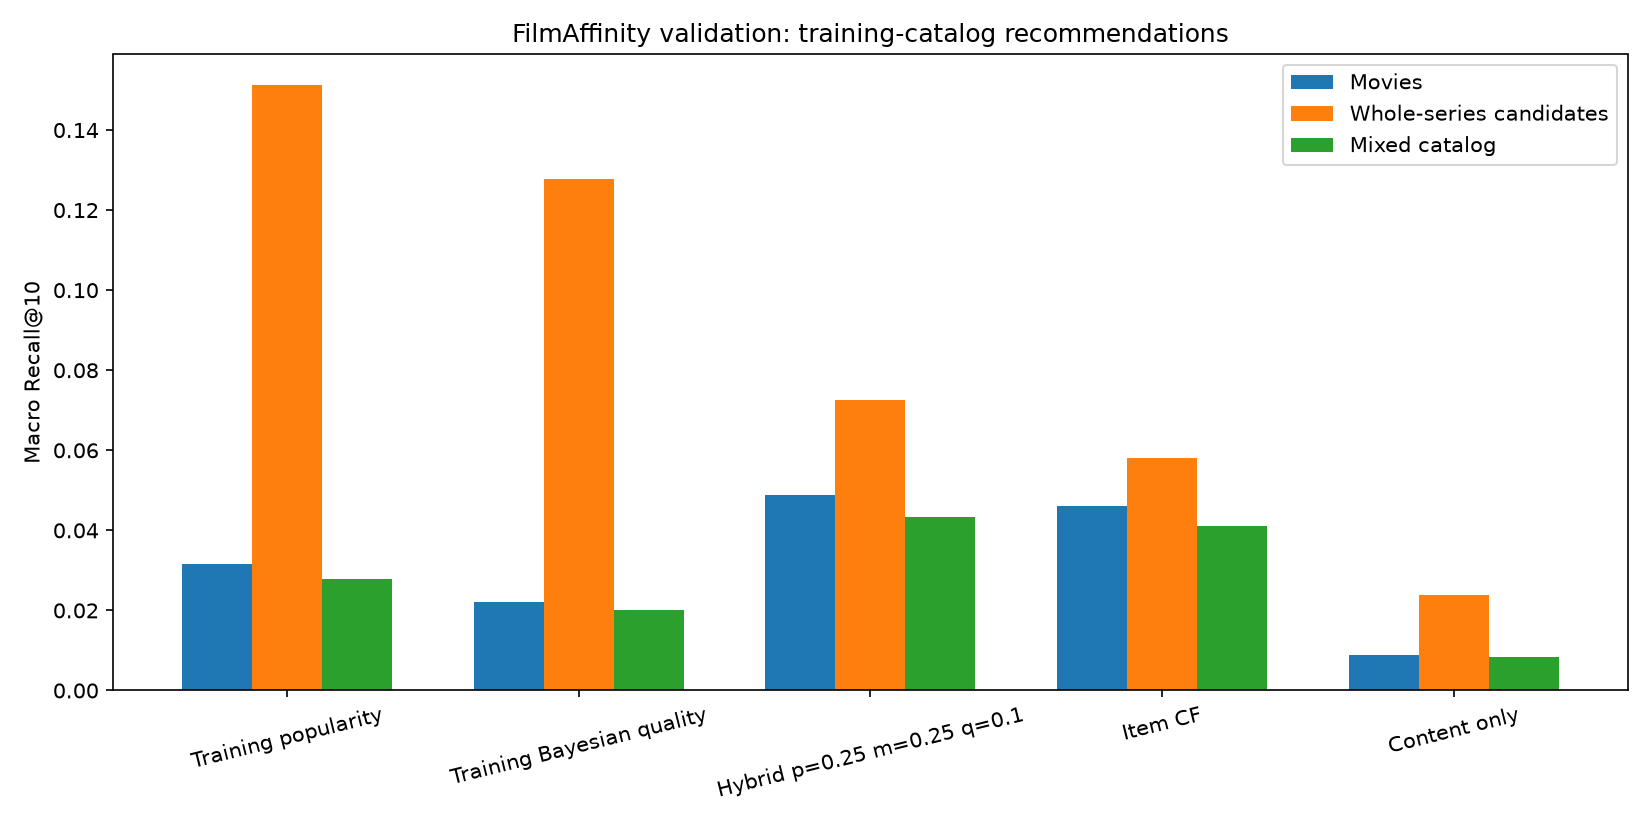

In [4]:
leaderboard = pd.read_csv(OUTPUT / 'leaderboard.csv')
with pd.option_context('display.max_columns', None, 'display.max_rows', None):
    display(leaderboard)
display(Image(filename=str(OUTPUT / 'validation_comparison.png')))

## What this run found

The cohort contains **5,505 established users**, with **173,232 training ratings** across **8,995 movie candidates and 1,727 whole-series candidates**. Series account for 10,697 training ratings. Validation has **985 users with at least one series like** and **3,830 with at least one movie like**; these cohorts differ but stay fixed across models.

| Model | Movie-only Recall@10 | Series-only Recall@10 | Mixed-list Recall@10 | Balanced movie/TV Recall@10 |
|---|---:|---:|---:|---:|
| Training popularity | 0.031684 | **0.151309** | 0.027804 | **0.091496** |
| Item collaborative filtering | 0.046070 | 0.058050 | 0.041024 | 0.052060 |
| Best personalized hybrid | **0.048873** | 0.072629 | **0.043430** | 0.060751 |

The best personalized hybrid uses **p=0.25, m=0.25, q=0.10**. It improves series-only recall from 5.81% to 7.26% versus plain CF, about **25.1% relative**. Its movie and mixed-list recall also improve. These are macro averages of the fraction of each user's held-out likes recovered in ten recommendations, not percentage prediction accuracy.

**Popularity still wins the prespecified balanced objective.** It is an important benchmark, not evidence that we have solved personalized TV recommendations. Review-associated feedback, limited TV histories, and preference concentration may contribute; this study does not isolate their causal effects. Content alone is weak here, and 4,526 training titles have no training likes at the >=8 threshold. Missing CF support is not a dislike.

The saved bundle contains both the overall selected variant and the best personalized hybrid settings. No app model is replaced. MovieLens/LLM benchmark scores measure different populations and cannot be compared directly with this table. Paired validation intervals are descriptive because this same validation set selected the weights.

The next focused experiment should compare a training-popularity TV fallback with personalized scoring as TV history grows, and explicitly calibrate movie-versus-series exposure in the mixed feed. Keep the new test split reserved until a final model and evaluation rule are fixed.


## Selected model and component settings

The saved selection record identifies the chosen model, its components, and the validation rule. A winning row is a validation-selected result and needs a later independent test or prospective user study before a general accuracy claim.

In [5]:
print('Winner under the prespecified balanced movie/TV objective:')
display(report['best_model'])
print('Best personalized hybrid under that same objective:')
display(report['best_personalized_model'])
selection = json.loads((OUTPUT / 'selection.json').read_text(encoding='utf-8'))
display(selection)
intervals = pd.read_csv(OUTPUT / 'paired_validation_intervals.csv')
display(intervals.loc[(intervals['model'] == report['best_personalized_model']['model']) & (intervals['baseline'] == 'Item CF')])


Winner under the prespecified balanced movie/TV objective:
Best personalized hybrid under that same objective:


{'model': 'Training popularity',
 'kind': 'popularity',
 'plot': 0.0,
 'metadata': 0.0,
 'quality': 0.0,
 'mixed_users': 4146,
 'mixed_recall_at_10': 0.02780423650106121,
 'mixed_ndcg_at_10': 0.019507831501850294,
 'movie_users': 3830,
 'movie_recall_at_10': 0.031683730205042566,
 'movie_ndcg_at_10': 0.02182161560551442,
 'whole_series_users': 985,
 'whole_series_recall_at_10': 0.15130885752713163,
 'whole_series_ndcg_at_10': 0.08561715800350789,
 'balanced_recall_at_10': 0.0914962938660871,
 'weight_total': 0.0}

{'model': 'Hybrid p=0.25 m=0.25 q=0.1',
 'kind': 'hybrid',
 'plot': 0.25,
 'metadata': 0.25,
 'quality': 0.1,
 'mixed_users': 4146,
 'mixed_recall_at_10': 0.04342966279908722,
 'mixed_ndcg_at_10': 0.033835097696640115,
 'movie_users': 3830,
 'movie_recall_at_10': 0.04887331911463026,
 'movie_ndcg_at_10': 0.037075161107435355,
 'whole_series_users': 985,
 'whole_series_recall_at_10': 0.0726293982385353,
 'whole_series_ndcg_at_10': 0.0386837175128756,
 'balanced_recall_at_10': 0.06075135867658278,
 'weight_total': 0.6}

{'selected_variant': {'model': 'Training popularity',
  'kind': 'popularity',
  'plot': 0.0,
  'metadata': 0.0,
  'quality': 0.0},
 'best_model': {'model': 'Training popularity',
  'kind': 'popularity',
  'plot': 0.0,
  'metadata': 0.0,
  'quality': 0.0,
  'mixed_users': 4146,
  'mixed_recall_at_10': 0.02780423650106121,
  'mixed_ndcg_at_10': 0.019507831501850294,
  'movie_users': 3830,
  'movie_recall_at_10': 0.031683730205042566,
  'movie_ndcg_at_10': 0.02182161560551442,
  'whole_series_users': 985,
  'whole_series_recall_at_10': 0.15130885752713163,
  'whole_series_ndcg_at_10': 0.08561715800350789,
  'balanced_recall_at_10': 0.0914962938660871,
  'weight_total': 0.0},
 'best_personalized_variant': {'model': 'Hybrid p=0.25 m=0.25 q=0.1',
  'kind': 'hybrid',
  'plot': 0.25,
  'metadata': 0.25,
  'quality': 0.1},
 'best_personalized_model': {'model': 'Hybrid p=0.25 m=0.25 q=0.1',
  'kind': 'hybrid',
  'plot': 0.25,
  'metadata': 0.25,
  'quality': 0.1,
  'mixed_users': 4146,
  'mixed_

,baseline,task,users,mean_recall_difference,lower_95,upper_95,model,interpretation
15,Item CF,mixed,4146,0.002406,-0.000060,0.004813,Hybrid p=0.25 m=0.25 q=0.1,Descriptive validation interval after model se...
16,Item CF,movie,3830,0.002804,-0.000239,0.005668,Hybrid p=0.25 m=0.25 q=0.1,Descriptive validation interval after model se...
17,Item CF,whole_series,985,0.014579,0.004467,0.024803,Hybrid p=0.25 m=0.25 q=0.1,Descriptive validation interval after model se...


## Per-user results and recommendation examples

Inspect individual rows to see where movie and series behavior differs. Examples illustrate ranked output; they do not replace aggregate validation. FilmAffinity author IDs remain source-specific pseudonymous identifiers.

The complete tables are saved as [validation per-user results](../data/processed/notebook17_filmaffinity/validation_per_user.csv) and [recommendation examples](../data/processed/notebook17_filmaffinity/recommendation_examples.csv).

In [6]:
per_user = pd.read_csv(OUTPUT / 'validation_per_user.csv')
examples = pd.read_csv(OUTPUT / 'recommendation_examples.csv')
print(f'Per-user validation rows: {len(per_user):,}')
display(per_user.head(12))
print(f'Saved recommendation example rows: {len(examples):,}')
with pd.option_context('display.max_columns', None):
    display(examples.head(30))

Per-user validation rows: 44,805
Saved recommendation example rows: 300


,model,task,user_id,recall_at_10,ndcg_at_10,hits
0,Training popularity,mixed,fa:100146,0.000000,0.000000,0
1,Training popularity,mixed,fa:100229,0.000000,0.000000,0
2,Training popularity,mixed,fa:100341,0.000000,0.000000,0
3,Training popularity,mixed,fa:100948,0.026316,0.205117,2
4,Training popularity,mixed,fa:100954,0.000000,0.000000,0
5,Training popularity,mixed,fa:101197,0.000000,0.000000,0
6,Training popularity,mixed,fa:101814,0.000000,0.000000,0
7,Training popularity,mixed,fa:1019144,0.000000,0.000000,0
8,Training popularity,mixed,fa:101995,0.000000,0.000000,0
9,Training popularity,mixed,fa:102262,0.000000,0.000000,0


,model,user_id,task,rank,item_id,title,original_title,unit,confidence,validation_hit
0,Training popularity,fa:100146,mixed,1,film160882,Pulp Fiction,Pulp Fiction,movie,medium,False
1,Training popularity,fa:100146,mixed,2,film358476,Blade Runner,Blade Runner,movie,medium,False
2,Training popularity,fa:100146,mixed,3,film539054,Gran Torino,Gran Torino,movie,medium,False
3,Training popularity,fa:100146,mixed,4,film708792,"Alien, el octavo pasajero",Alien,movie,medium,False
4,Training popularity,fa:100146,mixed,5,film656153,La lista de Schindler,Schindler's List,movie,medium,False
5,Training popularity,fa:100146,mixed,6,film161026,Cadena perpetua,The Shawshank Redemption,movie,medium,False
6,Training popularity,fa:100146,mixed,7,film695647,Match Point,Match Point,movie,medium,False
7,Training popularity,fa:100146,mixed,8,film746997,Malditos bastardos,Inglourious Basterds,movie,medium,False
8,Training popularity,fa:100146,mixed,9,film598422,El resplandor,The Shining,movie,medium,False
9,Training popularity,fa:100146,mixed,10,film313601,El secreto de sus ojos,El secreto de sus ojos,movie,medium,False


## Interpretation and limits

- This is a fresh movie/series training experiment on FilmAffinity users. It evaluates a model structure inspired by the prior winner; it does not establish that one dataset's raw score beats another dataset or an LLM.
- Review-associated feedback, active-user eligibility, inferred content units, ambiguous cast names, current metadata, and review-date proxies limit the conclusions. A whole-series candidate label is not independently verified.
- Domain coverage and separate movie/TV metrics matter: a high mixed score can conceal poor TV performance. The selection objective is fixed before inspecting the validation results.
- The reserved FilmAffinity test remains unused for selection. No old MovieLens test feedback is opened.
- A fitted joblib model and the report/selection tables are saved under [the notebook-17 output folder](../data/processed/notebook17_filmaffinity/). Loading joblib files is appropriate only for trusted artifacts created by this project.
- No app model is automatically replaced, and no paid service is called. Hosting or deployment is separate work.

Use the selected row and its domain metrics as the result of this notebook. Further tuning requires a new validation plan rather than repeatedly consulting the reserved test.

## Do series actually appear in a mixed recommendation list?

Series-only Recall ranks only series, while movie-only Recall ranks only movies. They describe separate shelves. A mixed top ten can contain few series even if a series-only shelf performs well. The following **post-selection diagnostics** compare the frozen overall winner and best personalized hybrid without retuning either model. They verify their reproduced mixed and series-only recall against the recorded leaderboard.

For the same mixed list, report movie and series recall separately, series exposure, and results for users with and without a training series like. The latter is a cross-domain profile check, not a new-user or unseen-title cold-start study. All held-out relevant titles remain in the denominators. No reserved-test scores are used.


In [7]:
from scripts.filmaffinity_diagnostics import analyze_selected_model

diagnostics = analyze_selected_model(ROOT)
display(diagnostics)


Diagnostics: verifying frozen model, validation, source catalog, leaderboard, and runner hashes...
Diagnostics: loading trusted trained_model.joblib (0.1s)...
Diagnostics: scoring 4,146 users for 2 fixed models in batches of 128...
Diagnostics: 128/4,146 users x 2 models (2.6s).
Diagnostics: 1,024/4,146 users x 2 models (7.0s).
Diagnostics: 2,048/4,146 users x 2 models (12.0s).
Diagnostics: 3,072/4,146 users x 2 models (18.5s).
Diagnostics: 4,096/4,146 users x 2 models (24.2s).
Diagnostics: 4,146/4,146 users x 2 models (24.4s).
Diagnostics saved; 4 leaderboard parity checks passed (24.7s).


{'created_at': '2026-11-09T04:56:41.971676+00:00',
 'elapsed_seconds': 24.665157300012652,
 'selected_model_name': 'Training popularity',
 'best_personalized_model_name': 'Hybrid p=0.25 m=0.25 q=0.1',
 'models': [{'model': 'Training popularity',
   'variant': {'model': 'Training popularity',
    'kind': 'popularity',
    'plot': 0.0,
    'metadata': 0.0,
    'quality': 0.0},
   'roles': ['selected_by_original_balanced_objective'],
   'mixed_exposure': {'all_validation_positive_users': {'users': 4146,
     'mean_user_tv_share_at_10': 0.000241196333815726,
     'pooled_tv_share_at_10': 0.000241196333815726,
     'fraction_users_with_at_least_one_tv': 0.001929570670525808,
     'mean_tv_count_at_10': 0.00241196333815726,
     'mixed_recall_at_10': 0.02780423650106121,
     'mixed_ndcg_at_10': 0.019507831501850294},
    'tv_positive_users': {'users': 985,
     'mean_user_tv_share_at_10': 0.0005076142131979696,
     'pooled_tv_share_at_10': 0.0005076142131979696,
     'fraction_users_with_a

### The mixed feed still needs calibration

| Frozen model | TV share of mixed top-ten slots | TV Recall from that actual mixed list | TV-only Recall, same 985 users |
|---|---:|---:|---:|
| Training popularity | 0.024% | 0.025% | 15.131% |
| Best personalized hybrid | 7.004% | 0.439% | 7.263% |

TV exposure uses all 4,146 validation-positive users. Both TV Recall columns use the same 985 TV-positive users, so the difference comes from competing movies in the ten available recommendation slots. The popularity winner for separate shelves is therefore a poor default for a mixed movie/series feed.

The hybrid places at least one series in the mixed top ten for **23.01%** of validation-positive users. Even so, its 7.26% TV-only recall drops to **0.44%** in the actual mixed list. This reproduces the concern from notebook 15: candidate support and good filtered rankings do not alone ensure useful TV placement beside movies.

Among TV-positive users, **321 have no training TV likes** (305 do have movie likes) and **664 have at least one training TV like**. The diagnostic output reports both groups. These are descriptive profile-transfer checks on the same validation set, not evidence of a causal benefit or new-user performance.

The next experiment should compare separate movie/TV shelves with a calibrated mixed ranking, and test whether a training-popularity TV fallback helps sparse TV profiles. A fixed TV quota may increase exposure but must be evaluated; this run does not establish that it improves preference accuracy. Do not promote the popularity winner into the app solely from the balanced separate-shelf score.


## Try the saved personalized model

This editable example profile uses FilmAffinity IDs for Breaking Bad, The Wire, Pulp Fiction and Blade Runner. The scores are illustrative, not a real person's evaluation data. Values can include hundredths; this binary-profile experiment still classifies >=8 as a like. Every rated title is excluded even if rated below 8. The score in the recommendation table is a ranking score, not a predicted 1-10 rating.

The saved overall selected variant is popularity. For a personalized demonstration, explicitly select the saved best hybrid settings below. This does not change the validation winner or app model. Whole-series labels remain provisional metadata inferences.


In [8]:
import joblib
from scripts.filmaffinity_experiment import recommend

fitted_bundle = joblib.load(OUTPUT / 'trained_model.joblib')
personalized_bundle = {**fitted_bundle, 'selected_variant': fitted_bundle['best_personalized_variant']}
example_profile = {
    'film489970': 9.25,  # Breaking Bad
    'film399474': 9.00,  # The Wire
    'film160882': 8.75,  # Pulp Fiction
    'film358476': 6.50,  # Blade Runner: excluded, not part of liked profile
}
print('Illustrative mixed recommendations from the saved personalized hybrid:')
display(recommend(personalized_bundle, example_profile, kind='mixed'))
print('Illustrative whole-series recommendations from the same profile:')
display(recommend(personalized_bundle, example_profile, kind='whole_series'))


Illustrative mixed recommendations from the saved personalized hybrid:
Illustrative whole-series recommendations from the same profile:


,item_id,title,original_title,year,unit,confidence,score
0,film402150,Los Soprano,The Sopranos,1999,whole_series,high,1.281139
1,film575149,Seven,Seven (Se7en),1995,movie,medium,1.087577
2,film264634,The Shield: Al margen de la ley,The Shield,2002,whole_series,high,1.016177
3,film596790,Mad Men,Mad Men,2007,whole_series,high,0.990663
4,film161026,Cadena perpetua,The Shawshank Redemption,1994,movie,medium,0.983383
5,film730528,El padrino. Parte II,The Godfather Part IIaka,1974,movie,medium,0.966394
6,film226427,El señor de los anillos: El retorno del rey,The Lord of the Rings: The Return of the King,2003,movie,medium,0.962169
7,film262689,Deadwood,Deadwood,2004,whole_series,high,0.931105
8,film482444,Dexter,Dexter,2006,whole_series,high,0.923949
9,film712576,Treme,Treme,2010,whole_series,high,0.912209


,item_id,title,original_title,year,unit,confidence,score
0,film402150,Los Soprano,The Sopranos,1999,whole_series,high,1.281139
1,film264634,The Shield: Al margen de la ley,The Shield,2002,whole_series,high,1.016177
2,film596790,Mad Men,Mad Men,2007,whole_series,high,0.990663
3,film262689,Deadwood,Deadwood,2004,whole_series,high,0.931105
4,film482444,Dexter,Dexter,2006,whole_series,high,0.923949
5,film712576,Treme,Treme,2010,whole_series,high,0.912209
6,film233858,Orange Is the New Black,Orange Is the New Black,2013,whole_series,high,0.870177
7,film781297,Fargo,Fargo,2014,whole_series,medium,0.829869
8,film350166,Broadchurch,Broadchurch,2013,whole_series,high,0.809020
9,film585998,A dos metros bajo tierra,Six Feet Under,2001,whole_series,high,0.808047
